In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import time


from utils_ML import score_dataset
from utils_preproces import ols_fit, y_distribution_plot, corr_heatmap_plot, make_mi_scores, preprocess_data

from sklearn.ensemble import RandomForestRegressor, VotingRegressor, ExtraTreesRegressor
from xgboost import XGBRegressor, plot_importance
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor


from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold


from sklearn.metrics import mean_absolute_error

import random
from heapq import nsmallest

In [2]:
# Set Matplotlib defaults
plt.style.use("seaborn-v0_8-white")
plt.rc("figure", autolayout=True)
plt.rc(
    "axes",
    labelweight="bold",
    labelsize="large",
    titleweight="bold",
    titlesize=14,
    titlepad=10,
)

In [3]:
# Fix random state
random_state = 42

In [4]:
harps = pd.read_csv('harps_sample.csv')
apogee = pd.read_csv('apogee_sample.csv')
galah = pd.read_csv('galah_sample.csv')
gr8 = pd.read_csv('gr8_not_in_harps_sample.csv')

print (f'harps contains {len(harps)} stars')
print (f'apogee contains {len(apogee)} stars')    
print (f'galah contains {len(galah)} stars')
print (f'gr8 contains {len(gr8)} stars')

harps contains 798 stars
apogee contains 95586 stars
galah contains 116050 stars
gr8 contains 1430 stars


In [5]:
apogee = apogee[apogee.parallax >0.5]
print (len(apogee))
galah = galah[galah.parallax > 2]
print (len(galah))


36109
45103


# Here we focus on getting Fe from no abundance

In [6]:
def fit_trasform(X):
    X['VW_lsr'] = np.sqrt(X['V_lsr']**2 + X['W_lsr']**2)
    X['UW_lsr'] = np.sqrt(X['U_lsr']**2 + X['W_lsr']**2)
    X['UV_lsr'] = np.sqrt(X['U_lsr']**2 + X['V_lsr']**2)
    X['UVW_lsr'] = np.sqrt(X['U_lsr']**2 + X['V_lsr']**2 + X['W_lsr']**2)
    epsilon = 1e-6
    #log features
    #X['Log_RV'] = np.log(X['RV'] + np.abs(X['RV'].min()))
    #X['Log_U_lsr'] = np.log(X['U_lsr'] + np.abs(X['U_lsr'].min()) + epsilon)
    #X['Log_V_lsr'] = np.log(X['V_lsr'] + np.abs(X['V_lsr'].min()) + epsilon)
    X['abs_W_lsr'] =np.abs(X['W_lsr'])
    #X['abs_U_lsr'] =np.abs(X['U_lsr'])
    #X['Log_UW_lsr'] = np.log(X['UW_lsr'])
    X['Log_UVW_lsr'] = np.log(X['UVW_lsr'])
    X.drop(columns = ['U_lsr', 'W_lsr'], inplace = True)

    return X

apogee = fit_trasform(apogee)
harps = fit_trasform(harps)
galah = fit_trasform(galah)
gr8 = fit_trasform(gr8)



columns_for_Fe = ['zmax',
 'jz',
 'P_gal',
 'Log_UVW_lsr',
 'VW_lsr',
 'UVW_lsr',
 'jp',
 'Tz',
 'Oz',
 'jr',
 'eccentricity',
 'V_lsr',
 'abs_W_lsr',
 'rperi',
 'Or',
 'UW_lsr',
 'rapo',
 'fe_h']

apogee = apogee[columns_for_Fe]
harps = harps[columns_for_Fe]
galah = galah[columns_for_Fe]
gr8 = gr8[columns_for_Fe]




### Identifying and exluding null values

In [7]:
apogee.isnull().sum() # 196 null value for P_gal
apogee.dropna(inplace = True)

In [8]:
#galah.isnull().sum() # 1 null value for P_gal
#galah.dropna(inplace = True)

In [9]:
#gr8.isnull().sum() # No null values

In [10]:
#harps.isnull().sum() # No null values

In [11]:
apogee = apogee[(apogee.zmax < 10) & (apogee.jz < 300) & (apogee.Tz < 0.3)  & (apogee.jr < 3000) & (apogee.abs_W_lsr < 200) & (apogee.rapo.between(7, 20)) & (apogee.rperi.between(0, 9))]
apogee.shape

(34728, 18)

### Spliting data into Trianing and Testing sets

In [12]:
# Split APOGEE
apogee_train_full, apogee_test = train_test_split(apogee, test_size=0.1, random_state=random_state)
X_apogee_train = apogee_train_full.drop(columns=['fe_h'])
y_apogee_train = apogee_train_full['fe_h']

X_apogee_test = apogee_test.drop(columns=['fe_h'])
y_apogee_test = apogee_test['fe_h']

# Split GALAH
galah_train_full, galah_test = train_test_split(galah, test_size=0.3, random_state=random_state)
X_galah_train = galah_train_full.drop(columns=['fe_h'])
y_galah_train = galah_train_full['fe_h']

X_galah_test = galah_test.drop(columns=['fe_h'])
y_galah_test = galah_test['fe_h']

# Gr8 no split
X_gr8 = gr8.drop(columns=['fe_h'])
y_gr8 = gr8['fe_h']

# HARPS — no split
X_harps = harps.drop(columns=['fe_h'])
y_harps = harps['fe_h']

# Combine APOGEE and GALAH train sets
X_combined_train = pd.concat([X_apogee_train], ignore_index=True)
y_combined_train = pd.concat([y_apogee_train], ignore_index=True)

full_df = pd.concat([apogee,   harps], ignore_index=True)
X_full = full_df.drop(columns=['fe_h'])
y_full = full_df['fe_h']

In [13]:
from scikeras.wrappers import KerasRegressor
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
import tensorflow as tf
from tensorflow.keras import Input

def build_keras_regressor(input_dim, lr=0.001):
    model = Sequential([
        Input(shape=(input_dim,)), 
        Dense(64, activation='relu'),
        BatchNormalization(),
        Dropout(0.2),
        Dense(32, activation='relu'),
        BatchNormalization(),
        Dropout(0.2),
        Dense(16, activation='relu'),
        BatchNormalization(),
        Dropout(0.2),
        Dense(1)
    ])
    model.compile(optimizer=Adam(learning_rate=lr), loss='mae', metrics=['mae'])
    return model



dl_model = KerasRegressor(
    model=build_keras_regressor,
    model__lr=0.007,
    epochs=20,
    batch_size=64,
    verbose=0,
    #callbacks=[tf.keras.callbacks.EarlyStopping(monitor='mae', patience=5, restore_best_weights=True)]
    validation_split=0.2,
    callbacks=[tf.keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)]
)


2025-10-29 13:05:35.362389: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-10-29 13:05:35.450758: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1761743135.493983  109804 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1761743135.508634  109804 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1761743135.590610  109804 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking 

In [14]:
rfr = RandomForestRegressor(random_state=random_state, n_jobs=-1)
xgbr = XGBRegressor(random_state=random_state, n_jobs=-1)
lr = LinearRegression()  # no internal parallel
svr = SVR()  # no internal parallel
lgbr = LGBMRegressor(random_state=random_state, verbosity=-1, n_jobs=-1)
catr = CatBoostRegressor(random_state=random_state, verbose=False, thread_count=-1)
extr = ExtraTreesRegressor(random_state=random_state, n_jobs=-1)


voting_r = VotingRegressor(estimators=[
    ('xgbr', xgbr),
    #('rfr', rfr),
    ('extr', extr),
    ('lgbr', lgbr),
    ('catr', catr)
])

model_names = {
    #'dl_model': dl_model,
    'xgbr': xgbr,
    #'rfr': rfr,
    'extr': extr,  
    #'svr': svr,
    #'lr': lr,
    'lgbr': lgbr,
    'catr': catr,
    #'voting_r': voting_r 
}


In [15]:
def model_test_CV_models(X, y, models, k=5, random_state=random_state):
    """
    Perform k-fold cross-validation for multiple models and return mean MAE scores and elapsed time.

    Parameters:
        X (DataFrame): Feature matrix.
        y (Series): Target vector.
        models (dict): Dictionary of model_name: model_instance.
        k (int): Number of folds.
        random_state (int): Seed for reproducibility.

    Returns:
        dict: {model_name: {'mean_mae': ..., 'std_mae': ..., 'time_sec': ...}}
    """
    kf = KFold(n_splits=k, shuffle=True, random_state=random_state)
    results = {}

    for name, model in models.items():
        print(f"Scoring model: {name}")
        start_time = time.time()
        mae_scores = []

        for train_index, test_index in kf.split(X, y):
            X_train, X_test = X.iloc[train_index], X.iloc[test_index]
            y_train, y_test = y.iloc[train_index], y.iloc[test_index]

            # Special handling for scikeras models
            if isinstance(model, KerasRegressor):
                model.set_params(model__input_dim=X_train.shape[1])

            model.fit(X_train, y_train)
            y_pred = model.predict(X_test)
            mae = mean_absolute_error(y_test, y_pred)
            mae_scores.append(mae)

        elapsed_time = time.time() - start_time
        results[name] = {
            'mean_mae': np.mean(mae_scores),
            'std_mae': np.std(mae_scores),
            'time_sec': elapsed_time
        }

        print(f"{name} done in {elapsed_time:.2f}s → MAE: {results[name]['mean_mae']:.3f} ± {results[name]['std_mae']:.3f}\n")

    return results


In [16]:
baseline_results = model_test_CV_models(X_combined_train, y_combined_train, model_names, k=5)

for name, score in baseline_results.items():
    print(f"{name:8s} | MAE: {score['mean_mae']:.3f} ± {score['std_mae']:.3f}")


Scoring model: xgbr
xgbr done in 1.59s → MAE: 0.154 ± 0.001

Scoring model: extr
extr done in 9.18s → MAE: 0.155 ± 0.001

Scoring model: lgbr
lgbr done in 10.20s → MAE: 0.150 ± 0.001

Scoring model: catr
catr done in 32.97s → MAE: 0.151 ± 0.001

xgbr     | MAE: 0.154 ± 0.001
extr     | MAE: 0.155 ± 0.001
lgbr     | MAE: 0.150 ± 0.001
catr     | MAE: 0.151 ± 0.001


In [17]:
def evaluate_on_test_data(X_train, y_train, test_df, target, models, test_name='Test'):
    """
    Trains models on the full training set and evaluates on a test set.

    Parameters:
        X_train, y_train: Training features and target.
        test_df: DataFrame containing the test data (including the target column).
        target (str): Name of the target column in test_df.
        models: Dictionary of model_name: model_instance.
        test_name (str): Label for this test set (e.g., 'Apogee', 'HARPS').

    Returns:
        dict: model_name → test MAE and baseline MAE
    """
    X_test = test_df.drop(columns=[target])
    y_test = test_df[target]

    results = {}

    for name, model in models.items():
        print(f"Training and evaluating {name} on {test_name}")
        model.fit(X_train, y_train)

        y_pred = model.predict(X_test)

        mae_model = mean_absolute_error(y_test, y_pred)
        mae_baseline = mean_absolute_error(y_test, [y_test.mean()] * len(y_test))

        results[name] = {
            'mae_model': mae_model,
            'mae_baseline': mae_baseline
        }

        print(f"{name} | {test_name} MAE: {mae_model:.3f} (mean baseline: {mae_baseline:.3f})\n")

    return results


In [18]:
# Evaluate on Apogee test
results_apogee = evaluate_on_test_data(
    X_combined_train, y_combined_train,
    test_df=apogee_test,
    target='fe_h',
    models=model_names,
    test_name='Apogee'
)

# Evaluate on HARPS test
results_harps = evaluate_on_test_data(
    X_combined_train, y_combined_train,
    test_df=harps,
    target='fe_h',
    models=model_names,
    test_name='HARPS'
)

# Evaluate on GALAH test
results_galah = evaluate_on_test_data(
    X_combined_train, y_combined_train,
    test_df=galah,
    target='fe_h',
    models=model_names,
    test_name='GALAH'
)

Training and evaluating xgbr on Apogee
xgbr | Apogee MAE: 0.155 (mean baseline: 0.181)

Training and evaluating extr on Apogee
extr | Apogee MAE: 0.156 (mean baseline: 0.181)

Training and evaluating lgbr on Apogee
lgbr | Apogee MAE: 0.151 (mean baseline: 0.181)

Training and evaluating catr on Apogee
catr | Apogee MAE: 0.152 (mean baseline: 0.181)

Training and evaluating xgbr on HARPS
xgbr | HARPS MAE: 0.177 (mean baseline: 0.204)

Training and evaluating extr on HARPS
extr | HARPS MAE: 0.177 (mean baseline: 0.204)

Training and evaluating lgbr on HARPS
lgbr | HARPS MAE: 0.174 (mean baseline: 0.204)

Training and evaluating catr on HARPS
catr | HARPS MAE: 0.175 (mean baseline: 0.204)

Training and evaluating xgbr on GALAH
xgbr | GALAH MAE: 0.154 (mean baseline: 0.161)

Training and evaluating extr on GALAH
extr | GALAH MAE: 0.157 (mean baseline: 0.161)

Training and evaluating lgbr on GALAH
lgbr | GALAH MAE: 0.151 (mean baseline: 0.161)

Training and evaluating catr on GALAH
catr | G

In [19]:
def plot_residuals_vs_features(X, y_true, y_pred, feature_names=None, model_name='Model', sample_name='Test Set'):
    """
    Plot residuals (y_true - y_pred) vs each feature in X.

    Parameters:
        X: DataFrame or array of features.
        y_true: True target values.
        y_pred: Predicted target values.
        feature_names: Optional list of feature names.
        model_name: For labeling plots.
        sample_name: Dataset name for titles.
    """
    import matplotlib.pyplot as plt
    import numpy as np
    import pandas as pd

    if isinstance(X, np.ndarray):
        X = pd.DataFrame(X, columns=feature_names if feature_names else [f'feature_{i}' for i in range(X.shape[1])])

    residuals = np.array(y_true) - np.array(y_pred)

    num_features = X.shape[1]
    ncols = 3
    nrows = int(np.ceil(num_features / ncols))

    fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(5 * ncols, 4 * nrows))

    for idx, col in enumerate(X.columns):
        ax = axes.flatten()[idx]
        ax.scatter(X[col], residuals, alpha=0.6, s=20)
        ax.axhline(0, color='gray', linestyle='--')
        ax.set_xlabel(col)
        ax.set_ylabel('Residual')
        ax.set_title(f'{col} vs Residual')

    for j in range(idx + 1, nrows * ncols):
        fig.delaxes(axes.flatten()[j])  # Remove empty subplots

    fig.suptitle(f'{model_name} Residuals vs Features ({sample_name})', fontsize=16)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()


In [20]:
import matplotlib.pyplot as plt
import numpy as np

def plot_residuals_vs_true(y_true, y_pred, model_name='Model', sample_name='Test Set'):
    """
    Plot residuals (y_true - y_pred) vs y_true, and residuals from predicting the mean.

    Parameters:
        y_true: Ground truth target values.
        y_pred: Model predictions.
        model_name: Name of the model for labeling.
        sample_name: Name of the dataset (e.g., 'Apogee' or 'HARPS').
    """
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    y_mean = np.full_like(y_true, y_true.mean())

    residuals_model = y_true - y_pred
    residuals_mean = y_true - y_mean

    plt.figure(figsize=(10, 6))
    plt.scatter(y_true, residuals_model, alpha=0.6, label=f'{model_name}', s=20)
    plt.scatter(y_true, residuals_mean, alpha=0.4, label='Mean predictor', s=20, marker='x')

    plt.axhline(0, color='gray', linestyle='--')
    plt.xlabel('True Value (y)')
    plt.ylabel('Residual (y_true - y_pred)')
    plt.title(f'Residuals vs True Values ({sample_name})')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


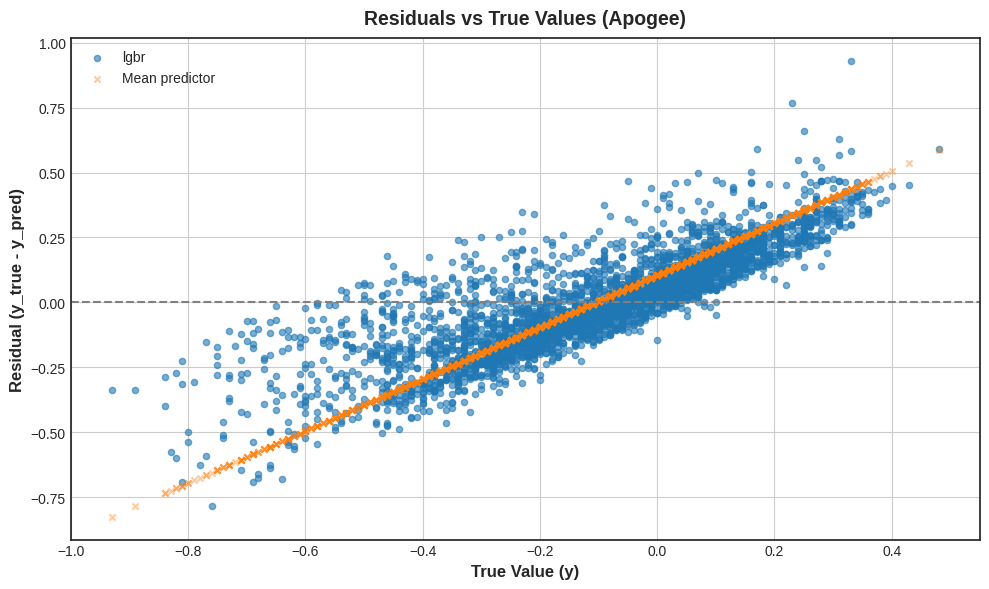

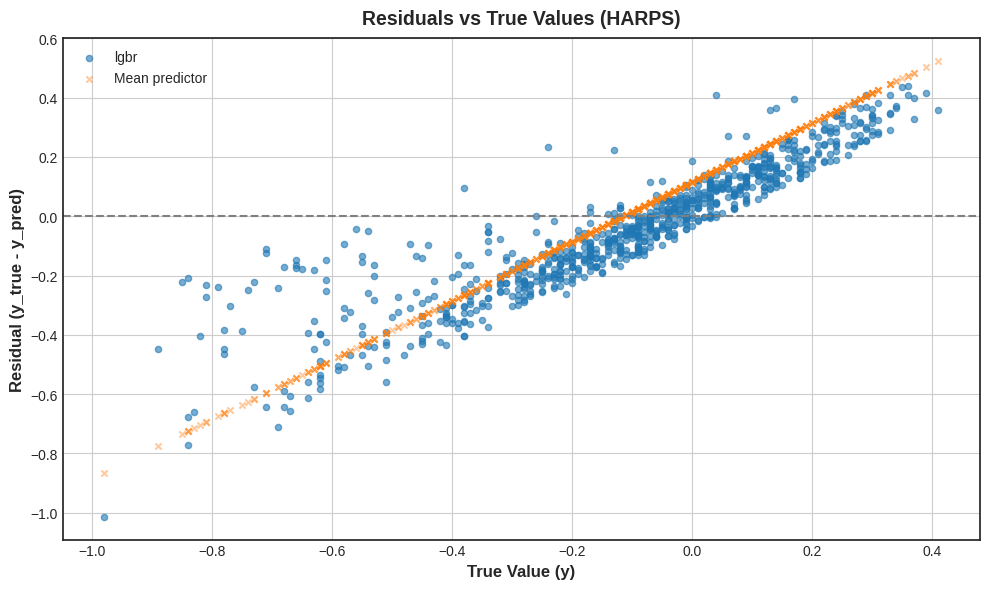

In [21]:
# Example for one model and one test set
best_model_name = 'lgbr'
model = model_names[best_model_name]
model.fit(X_combined_train, y_combined_train)

y_pred_apogee = model.predict(X_apogee_test)
plot_residuals_vs_true(y_apogee_test, y_pred_apogee, model_name=best_model_name, sample_name='Apogee')

y_pred_harps = model.predict(X_harps)
plot_residuals_vs_true(y_harps, y_pred_harps, model_name=best_model_name, sample_name='HARPS')

#y_pred_galah = model.predict(X_galah_test)
#plot_residuals_vs_true(y_galah_test, y_pred_galah, model_name=best_model_name, sample_name='GALAH')


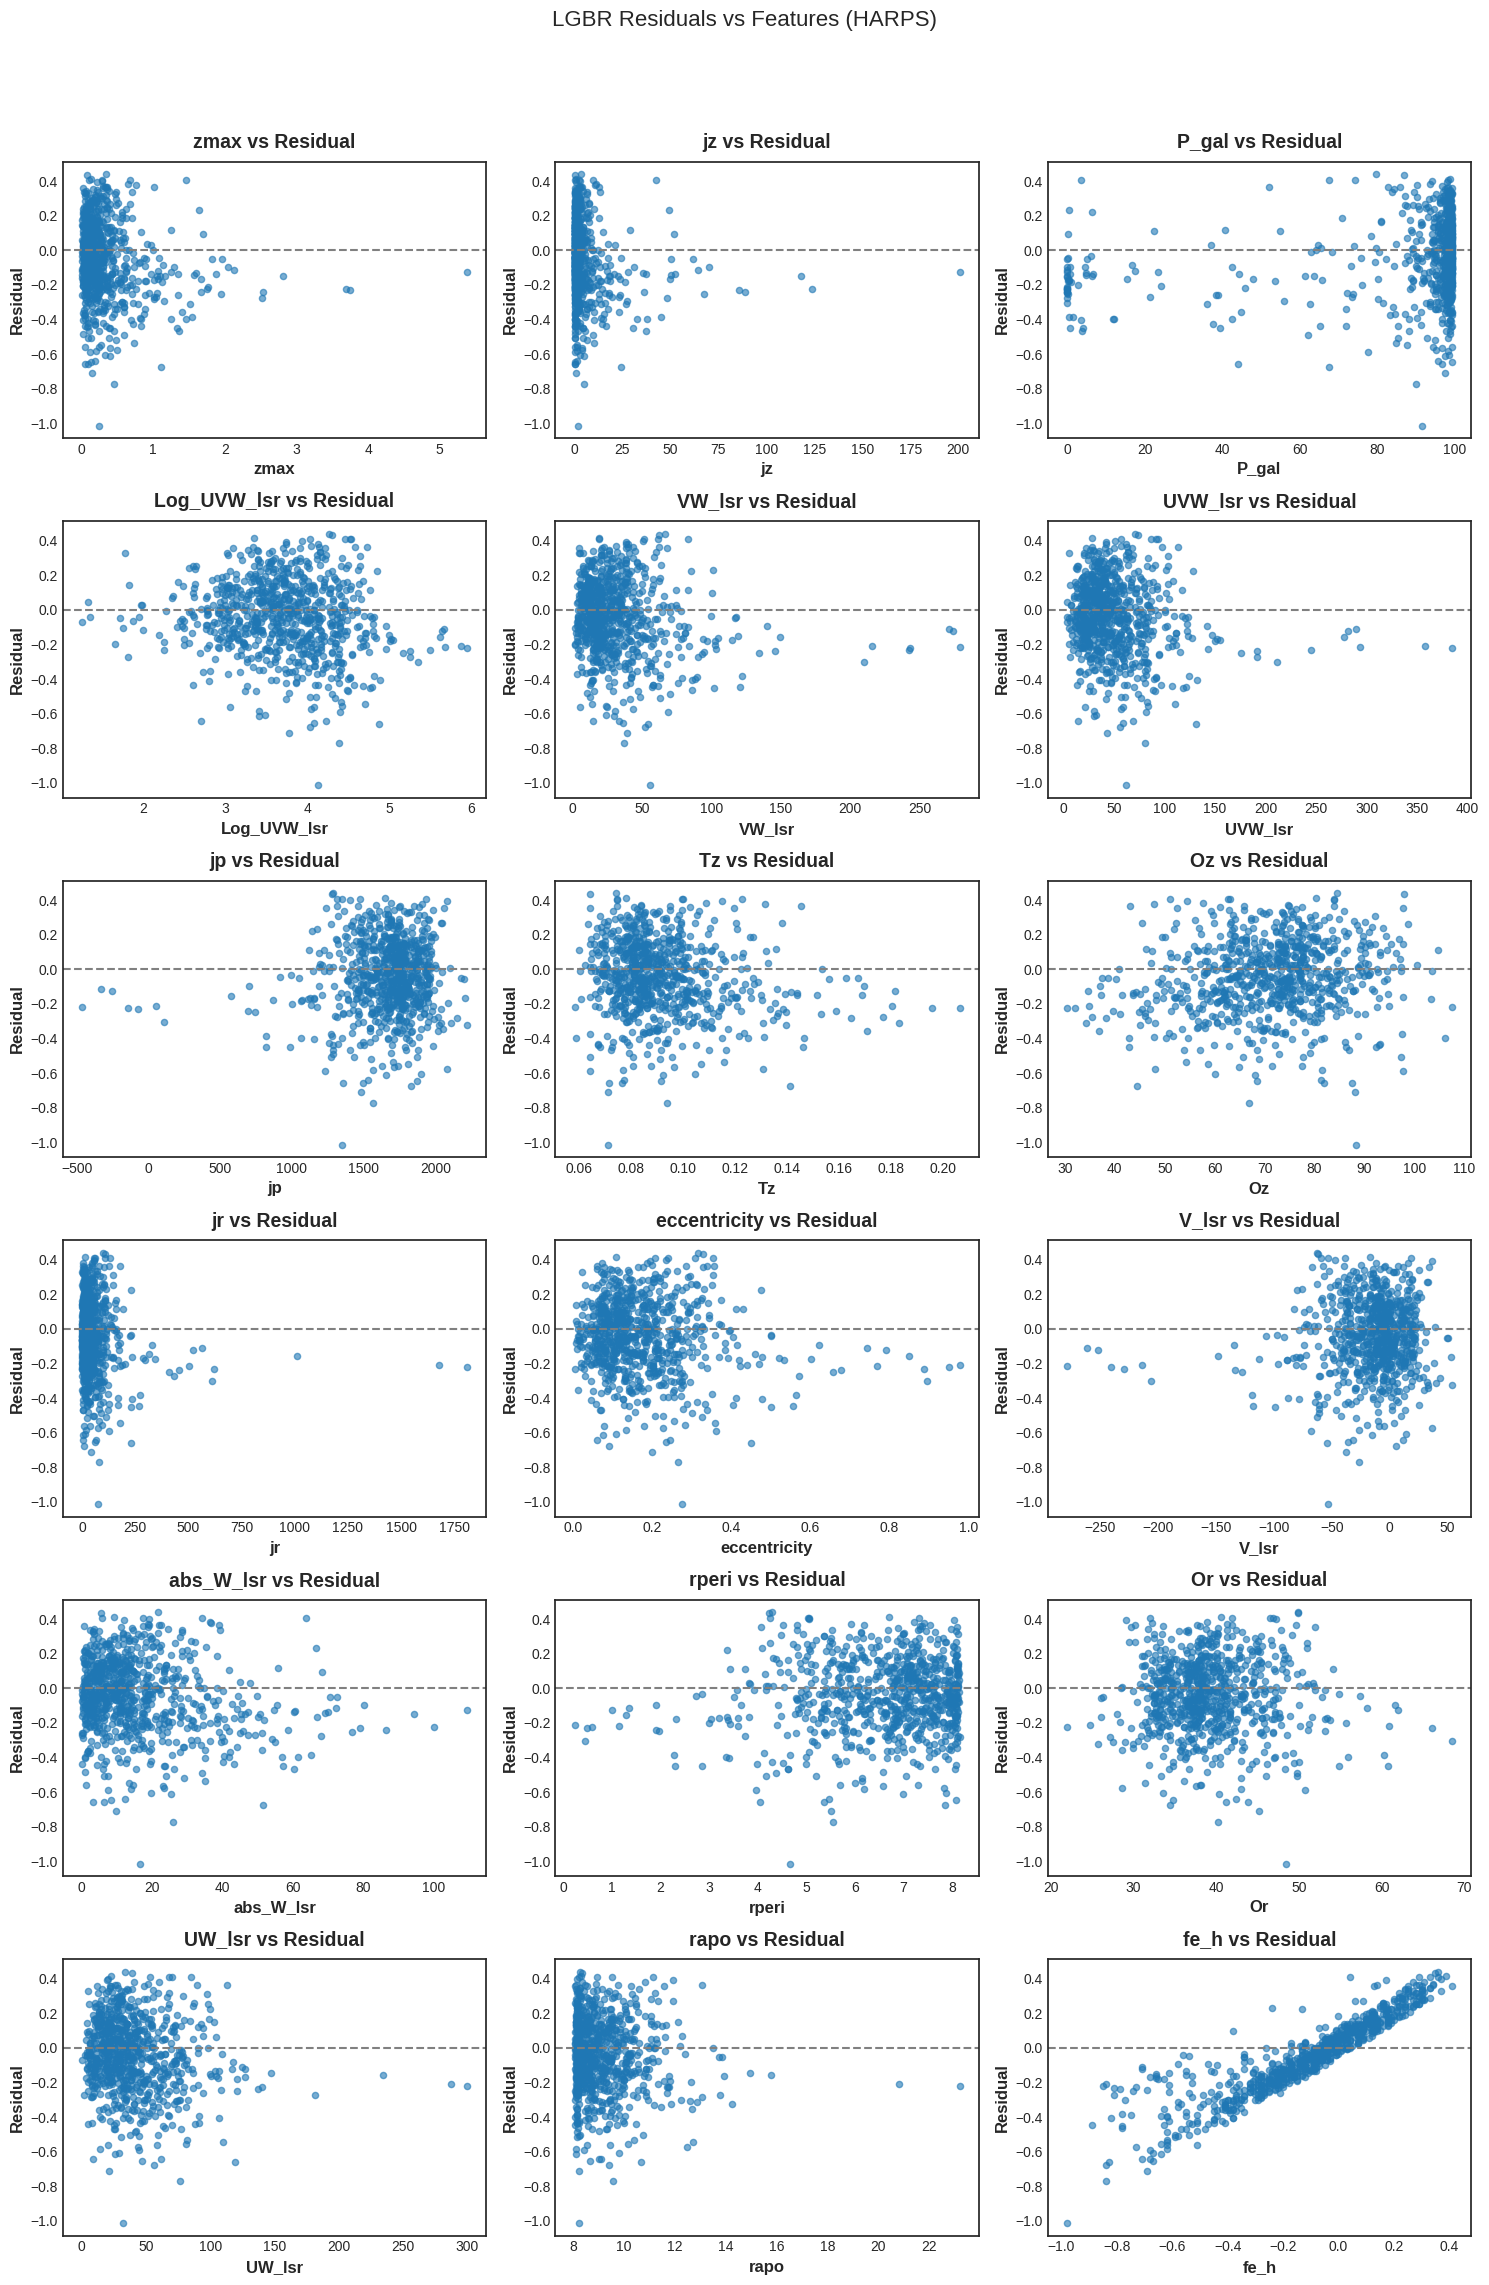

In [22]:
plot_residuals_vs_features(harps, y_harps, y_pred_harps, model_name='LGBR', sample_name='HARPS')

In [23]:
from copy import deepcopy
import random

class FeatureRemovingAdding:
    def __init__(self, verbose=True, tolerance=1e-5):
        self.verbose = verbose
        self.tolerance = tolerance
        self.history = []

    def _log(self, msg):
        if self.verbose:
            print(msg)

    def feature_to_remove(self, all_features, X, y, model_test_cv, maximize=True):
        best_score = model_test_cv(X[all_features], y)
        self._log(f'All features: {len(all_features)}')
        self._log(f'List of input features: {all_features}')
        self._log(f'With all features: score = {best_score:.5f}')

        best_feature_to_remove = None

        for i, feature in enumerate(all_features):
            test_feature = all_features.copy()
            test_feature.remove(feature)

            new_score = model_test_cv(X[test_feature], y)
            self._log(f'{i+1}/{len(all_features)}: Removing {feature} -> score = {new_score:.5f}')

            if ((maximize and new_score > best_score + self.tolerance) or
                (not maximize and new_score < best_score - self.tolerance)):
                self._log(f'New best score: {new_score:.5f} (was {best_score:.5f})')
                best_score = new_score
                best_feature_to_remove = feature

        return best_feature_to_remove

    def iterative_feature_removal(self, all_features, X, y, model_test_cv, min_features=2, maximize=True):
        all_features = all_features.copy()
        removed_features = []

        while len(all_features) > min_features:
            best_feature_to_remove = self.feature_to_remove(all_features.copy(), X, y, model_test_cv, maximize)
            if best_feature_to_remove is None:
                break

            removed_features.append(best_feature_to_remove)
            all_features.remove(best_feature_to_remove)
            self._log(f"Removing feature: {best_feature_to_remove}")
            self.history.append((len(all_features), model_test_cv(X[all_features], y)))

        self._log(f"Optimal set of features: {all_features}")
        self._log(f"All removed features: {removed_features}")
        return all_features

    def feature_to_add(self, all_features, removed_features, X, y, model_test_cv, maximize=True):
        best_score = model_test_cv(X[all_features], y)
        self._log(f'Current features: {len(all_features)}')
        self._log(f'With current features: score = {best_score:.5f}')

        best_feature_to_add = None

        for i, feature in enumerate(removed_features):
            test_feature = all_features.copy()
            test_feature.append(feature)

            new_score = model_test_cv(X[test_feature], y)
            self._log(f'{i+1}/{len(removed_features)}: Adding {feature} -> score = {new_score:.5f}')

            if ((maximize and new_score > best_score + self.tolerance) or
                (not maximize and new_score < best_score - self.tolerance)):
                self._log(f'New best score: {new_score:.5f} (was {best_score:.5f})')
                best_score = new_score
                best_feature_to_add = feature

        return best_feature_to_add

    def iterative_feature_adding(self, all_features, removed_features, X, y, model_test_cv, maximize=True):
        all_features = all_features.copy()
        removed_features = removed_features.copy()
        total_features = len(all_features) + len(removed_features)

        while len(all_features) < total_features:
            best_feature_to_add = self.feature_to_add(all_features.copy(), removed_features.copy(), X, y, model_test_cv, maximize)
            if best_feature_to_add is None:
                break

            all_features.append(best_feature_to_add)
            removed_features.remove(best_feature_to_add)
            self._log(f"Adding feature: {best_feature_to_add}")
            self.history.append((len(all_features), model_test_cv(X[all_features], y)))

        self._log(f"Optimal set of features: {all_features}")
        self._log(f"All remaining removed features: {removed_features}")
        return all_features
    
    

    def forward_backward_selection(self, X, y, model_test_cv, 
                                initial_features=None, 
                                all_features=None, 
                                maximize=True):
        if all_features is None:
            all_features = list(X.columns)

        if initial_features is None:
            initial_features = [random.choice(all_features)]
            self._log(f"Randomly selected initial feature: {initial_features[0]}")

        current_features = initial_features.copy()
        remaining_features = [f for f in all_features if f not in current_features]
        current_score = model_test_cv(X[current_features], y)
        self.history.append((len(current_features), current_score))
        self._log(f"Initial score with {current_features}: {current_score:.5f}")

        improved = True
        while improved:
            improved = False

            # === Try adding ===
            best_add, best_add_score = None, current_score
            for f in remaining_features:
                trial_features = current_features + [f]
                score = model_test_cv(X[trial_features], y)
                self._log(f"Trying to add {f}: score = {score:.5f}")

                if (maximize and score > best_add_score + self.tolerance) or \
                (not maximize and score < best_add_score - self.tolerance):
                    best_add, best_add_score = f, score

            if best_add:
                current_features.append(best_add)
                remaining_features.remove(best_add)
                current_score = best_add_score
                self.history.append((len(current_features), current_score))
                self._log(f"Added {best_add}, new score = {current_score:.5f}")
                improved = True

            # === Try removing ===
            best_remove, best_remove_score = None, current_score
            for f in current_features:
                trial_features = [x for x in current_features if x != f]
                score = model_test_cv(X[trial_features], y)
                self._log(f"Trying to remove {f}: score = {score:.5f}")

                if (maximize and score > best_remove_score + self.tolerance) or \
                (not maximize and score < best_remove_score - self.tolerance):
                    best_remove, best_remove_score = f, score

            if best_remove:
                current_features.remove(best_remove)
                remaining_features.append(best_remove)
                current_score = best_remove_score
                self.history.append((len(current_features), current_score))
                self._log(f"Removed {best_remove}, new score = {current_score:.5f}")
                improved = True

        self._log(f"Final feature set: {current_features} with score = {current_score:.5f}")
        return {
            'start': initial_features,
            'final_features': current_features,
            'final_score': current_score
        }

    
    def multi_start_forward_backward_selection(self, X, y, model_test_cv, 
                                        all_features=None, 
                                        maximize=True, 
                                        n_starts=10, 
                                        random_state=random_state):
        if all_features is None:
            all_features = list(X.columns)

        best_score = None
        best_result = None
        all_results = []

        rng = random.Random(random_state)

        for i in range(n_starts):
            start_feature = [rng.choice(all_features)]
            self._log(f"\n=== Run {i+1}/{n_starts} starting with: {start_feature[0]} ===")

            result = self.forward_backward_selection(
                X=X,
                y=y,
                model_test_cv=model_test_cv,
                initial_features=start_feature,
                all_features=all_features,
                maximize=maximize
            )

            all_results.append(result)

            if (maximize and (best_score is None or result['final_score'] > best_score)) or \
            (not maximize and (best_score is None or result['final_score'] < best_score)):
                best_score = result['final_score']
                best_result = result

        self._log(f"\n=== Summary of {n_starts} runs ===")
        for i, res in enumerate(all_results):
            self._log(f"{i+1}: Started with {res['start'][0]}, Final score = {res['final_score']:.5f}, Features: {res['final_features']}")

        self._log(f"\n>>> Best result: score = {best_result['final_score']:.5f}")
        self._log(f">>> Best feature set: {best_result['final_features']}")
        
        return best_result
    
    def random_search_with_greedy_refinement(self, X, y, model_test_cv, 
                                         all_features=None,
                                         maximize=False,
                                         n_random=20,
                                         top_k=3,
                                         subset_size_range=(2, 5),
                                         random_state=42):
        """
        Step 1: Try N random feature subsets and keep the top K by score.
        Step 2: Refine each of the top K using forward-backward selection.
        """

        if all_features is None:
            all_features = list(X.columns)

        rng = random.Random(random_state)
        evaluated_subsets = []

        print(f"\n--- RANDOM SEARCH PHASE ({n_random} trials) ---")
        for i in range(n_random):
            k = rng.randint(*subset_size_range)
            subset = rng.sample(all_features, k)
            score = model_test_cv(X[subset], y)
            evaluated_subsets.append({'subset': subset, 'score': score})
            print(f"{i+1}/{n_random}: Score = {score:.5f}, Features = {subset}")

        # Sort: best score first
        sorted_subsets = sorted(
            evaluated_subsets,
            key=lambda d: d['score'],
            reverse=maximize
        )

        print(f"\n--- TOP {top_k} SUBSETS TO REFINE ---")
        top_candidates = sorted_subsets[:top_k]
        for i, entry in enumerate(top_candidates):
            print(f"{i+1}: Score = {entry['score']:.5f}, Features = {entry['subset']}")

        print("\n--- GREEDY REFINEMENT PHASE ---")
        best_result = None
        best_score = None
        for i, entry in enumerate(top_candidates):
            print(f"\nRefining candidate {i+1}/{top_k}...")
            result = self.forward_backward_selection(
                X=X,
                y=y,
                model_test_cv=model_test_cv,
                initial_features=entry['subset'],
                all_features=all_features,
                maximize=maximize
            )
            score = result['final_score']
            print(f"Refined Score = {score:.5f}, Final Features = {result['final_features']}")

            if (maximize and (best_score is None or score > best_score)) or \
            (not maximize and (best_score is None or score < best_score)):
                best_score = score
                best_result = result

        print(f"\n>>> BEST FINAL RESULT: Score = {best_result['final_score']:.5f}")
        print(f">>> Feature Set = {best_result['final_features']}")

        return best_result






In [24]:
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error
import numpy as np

from sklearn.base import clone


def model_test_cv(X, y, model, k=5, random_state=42, scorer='mae'):
    kf = KFold(n_splits=k, shuffle=True, random_state=random_state)
    scores = []

    for train_index, test_index in kf.split(X):
        X_train, X_test = X.iloc[train_index], X.iloc[test_index]
        y_train, y_test = y.iloc[train_index], y.iloc[test_index]

        # Create a fresh clone of the model for each fold
        model_instance = clone(model)
        model_instance.fit(X_train, y_train)
        y_pred = model_instance.predict(X_test)

        if scorer == 'mae':
            scores.append(mean_absolute_error(y_test, y_pred))
        else:
            raise ValueError("Unsupported scorer: use 'mae'")

    return np.mean(scores)


In [25]:
def wrapped_cv(X, y):
    return model_test_cv(X, y, model=model, k=5, scorer='mae')

In [26]:
X_combined_train.columns

Index(['zmax', 'jz', 'P_gal', 'Log_UVW_lsr', 'VW_lsr', 'UVW_lsr', 'jp', 'Tz',
       'Oz', 'jr', 'eccentricity', 'V_lsr', 'abs_W_lsr', 'rperi', 'Or',
       'UW_lsr', 'rapo'],
      dtype='object')

In [27]:
all_features = ['zmax',
 'jz',
 'P_gal',
 'Log_UVW_lsr',
 'VW_lsr',
 'UVW_lsr',
 'jp',
 'Tz',
 'Oz',
 'jr',
 'eccentricity',
 'V_lsr',
 'abs_W_lsr',
 'rperi',
 'Or',
 'UW_lsr',
 'rapo']



#>>> BEST FINAL RESULT: Score = 0.15031
#>>> Feature Set = ['Oz', 'jp', 'rapo', 'zmax', 'Or', 'UVW_lsr', 'V_lsr', 'P_gal', 'jz', 'VW_lsr', 'Log_UVW_lsr']

In [28]:
fra = FeatureRemovingAdding(verbose=True)

best_features_result = fra.random_search_with_greedy_refinement(
    X=X_combined_train,
    y=y_combined_train,
    model_test_cv=wrapped_cv,
    all_features=all_features,
    maximize=False,
    n_random=200,
    top_k=5,
    subset_size_range=(2, 10),
    random_state=random_state
)



--- RANDOM SEARCH PHASE (200 trials) ---
1/200: Score = 0.15227, Features = ['zmax', 'Oz', 'Log_UVW_lsr']
2/200: Score = 0.15281, Features = ['VW_lsr', 'Log_UVW_lsr', 'eccentricity', 'V_lsr', 'Oz']
3/200: Score = 0.15266, Features = ['rperi', 'jz', 'zmax']
4/200: Score = 0.15191, Features = ['jp', 'Tz', 'Oz']
5/200: Score = 0.16441, Features = ['jp', 'rperi']
6/200: Score = 0.15077, Features = ['Or', 'Oz', 'abs_W_lsr', 'rperi', 'zmax']
7/200: Score = 0.15650, Features = ['rperi', 'eccentricity', 'VW_lsr', 'P_gal']
8/200: Score = 0.15073, Features = ['eccentricity', 'Log_UVW_lsr', 'jz', 'jp', 'Or']
9/200: Score = 0.15092, Features = ['V_lsr', 'Oz', 'abs_W_lsr', 'zmax', 'rapo', 'Tz', 'UW_lsr']
10/200: Score = 0.15425, Features = ['abs_W_lsr', 'P_gal', 'Oz']
11/200: Score = 0.15048, Features = ['V_lsr', 'jp', 'rapo', 'jz', 'zmax', 'eccentricity']
12/200: Score = 0.15108, Features = ['jr', 'P_gal', 'rperi', 'Log_UVW_lsr', 'jz']
13/200: Score = 0.15096, Features = ['Oz', 'Or', 'eccentricit

In [29]:
fra = FeatureRemovingAdding(verbose=True)

#best_features = fra.multi_start_forward_backward_selection(
#    X=X_combined_train,
#    y=y_combined_train,
#    model_test_cv=wrapped_cv,
#    all_features=all_features,
#    maximize=False,
#    n_starts=10
#)


In [30]:
from tpot import TPOTRegressor
from sklearn.model_selection import train_test_split

# Split data
X_train, X_test, y_train, y_test =     X_combined_train, X_harps, y_combined_train, y_harps

# Instantiate TPOT
tpot = TPOTRegressor(
    generations=5,             # number of evolutionary cycles
    population_size=20,         # number of models per generation
    verbosity=2,                # verbosity: 0 = silent, 3 = very detailed
    scoring='neg_mean_absolute_error',  # use MAE as metric
    random_state=random_state,
    n_jobs=-1                   # use all CPUs
)

# Fit TPOT
tpot.fit(X_train, y_train)

# Score on test set
print("Test MAE:", -tpot.score(X_test, y_test))  # negate because TPOT uses neg_MAE

# Export the best pipeline as Python code
tpot.export('best_pipeline.py')



/home/vadibekyan/anaconda3/lib/python3.12/site-packages/stopit/__init__.py:10: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


is_classifier
is_regressor
is_classifier
is_regressor
is_classifier
is_regressor
is_classifier
is_regressor
is_classifier
is_regressor
is_classifier
is_regressor


/home/vadibekyan/anaconda3/lib/python3.12/site-packages/sklearn/base.py:1206: FutureWarning: passing a class to None is deprecated and will be removed in 1.8. Use an instance of the class instead.
  warnings.warn(
/home/vadibekyan/anaconda3/lib/python3.12/site-packages/sklearn/base.py:1246: FutureWarning: passing a class to None is deprecated and will be removed in 1.8. Use an instance of the class instead.
  warnings.warn(


is_classifier
is_regressor
is_classifier
is_regressor
is_classifier
is_regressor
is_classifier
is_regressor
is_classifier
is_regressor
is_classifier
is_regressor
is_classifier
is_regressor
is_classifier
is_regressor
is_classifier
is_regressor
is_classifier
is_regressor
is_classifier
is_regressor
is_classifier
is_regressor
is_classifier
is_regressor
is_classifier
is_regressor
is_classifier
is_regressor
is_classifier
is_regressor
is_classifier
is_regressor
is_classifier
is_regressor
is_classifier
is_regressor
is_classifier
is_regressor
is_classifier
is_regressor
is_classifier
is_regressor
is_classifier
is_regressor
is_classifier
is_regressor


Version 0.12.2 of tpot is outdated. Version 1.1.0 was released Thursday July 03, 2025.


Optimization Progress:   0%|          | 0/120 [00:00<?, ?pipeline/s]

... (6 outputs left out)

/home/vadibekyan/anaconda3/lib/python3.12/site-packages/stopit/__init__.py:10: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/home/vadibekyan/anaconda3/lib/python3.12/site-packages/stopit/__init__.py:10: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/home/vadibekyan/anaconda3/lib/python3.12/site-packages/stopit/__init__.py:10: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setupt


Generation 4 - Current best internal CV score: -0.15023343594471752


/home/vadibekyan/anaconda3/lib/python3.12/site-packages/stopit/__init__.py:10: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/home/vadibekyan/anaconda3/lib/python3.12/site-packages/stopit/__init__.py:10: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/home/vadibekyan/anaconda3/lib/python3.12/site-packages/stopit/__init__.py:10: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setupt


Generation 5 - Current best internal CV score: -0.15017453353098653

Best pipeline: RandomForestRegressor(input_matrix, bootstrap=True, max_features=0.3, min_samples_leaf=20, min_samples_split=13, n_estimators=100)
Test MAE: 0.173011113804636
